In [1]:
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# 1. Initialisation de la SparkSession (avec connecteur PostgreSQL)
spark = SparkSession.builder \
    .appName('5SPAR-SentimentAnalysis') \
    .config('spark.sql.session.timeZone', 'UTC') \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.postgresql:postgresql:42.6.0") \
    .getOrCreate()

spark.sparkContext.setLogLevel('WARN')

# --- PARTIE A : ENTRAÎNEMENT SUR LE DATASET KAGGLE ---

print("--- Chargement et préparation des données Kaggle ---")
# Le CSV de Sentiment140 n'a pas d'en-tête. La colonne 0 est la cible (0=negatif, 4=positif), la colonne 5 est le texte.
kaggle_df = spark.read.csv("training.1600000.processed.noemoticon.csv", header=False, inferSchema=True)
kaggle_df = kaggle_df.select(F.col("_c0").alias("target"), F.col("_c5").alias("text"))

# Spark MLlib s'attend à une colonne 'label' avec des valeurs 0.0 et 1.0
# On transforme la cible Kaggle (4 devient 1.0 pour positif, 0 reste 0.0 pour négatif)
dataset = kaggle_df.withColumn("label", F.when(F.col("target") == 4, 1.0).otherwise(0.0))

# Séparation Train / Test (80% - 20%)
train_data, test_data = dataset.randomSplit([0.8, 0.2], seed=42)

print("--- Construction du Pipeline MLlib ---")
# Étape 1 : Découpage en mots
tokenizer = Tokenizer(inputCol="text", outputCol="words")

# Étape 2 : (Optionnelle mais recommandée) Retrait des mots de liaison (Stop Words)
remover = StopWordsRemover(inputCol=tokenizer.getOutputCol(), outputCol="filtered_words")

# Étape 3 : Conversion en vecteurs de fréquence (Term Frequency)
vectorizer = CountVectorizer(inputCol=remover.getOutputCol(), outputCol="rawFeatures")

# Étape 4 : Application du TF-IDF pour pénaliser les mots trop fréquents
idf = IDF(inputCol=vectorizer.getOutputCol(), outputCol="features")

# Étape 5 : Le modèle de classification (Régression Logistique)
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=10)

# Création du Pipeline complet
pipeline = Pipeline(stages=[tokenizer, remover, vectorizer, idf, lr])

print("--- Entraînement du modèle ---")
# Fit le pipeline sur les données d'entraînement (cela peut prendre quelques minutes selon ta machine)
model = pipeline.fit(train_data)

print("--- Évaluation du modèle ---")
predictions_test = model.transform(test_data)
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator.evaluate(predictions_test)
print(f"Précision (Accuracy) sur le jeu de test : {accuracy * 100:.2f}%")


# --- PARTIE B : APPLICATION BATCH SUR TES DONNÉES MASTODON (POSTGRESQL) ---

print("--- Chargement de l'historique Mastodon depuis PostgreSQL ---")
pg_host = os.getenv('PGHOST', 'postgres')
pg_db = os.getenv('PGDATABASE', 'mastodon')
pg_user = os.getenv('PGUSER', 'mastodon')
pg_password = os.getenv('PGPASSWORD', 'local_demo_change_me')

jdbc_url = f"jdbc:postgresql://{pg_host}:5432/{pg_db}"
connection_properties = {
    "user": pg_user,
    "password": pg_password,
    "driver": "org.postgresql.Driver"
}

mastodon_df = spark.read.jdbc(url=jdbc_url, table="toots", properties=connection_properties)

print("--- Analyse de sentiment sur Mastodon ---")
# On applique le modèle préalablement entraîné directement sur ton DataFrame Mastodon
mastodon_predictions = model.transform(mastodon_df)

# On mappe le résultat numérique (0.0 ou 1.0) vers un label textuel pour plus de lisibilité
final_results = mastodon_predictions.withColumn(
    "sentiment_label",
    F.when(F.col("prediction") == 1.0, "Positive").otherwise("Negative")
).select("instance", "id", "created_at", "text", "username", "sentiment_label")

final_results.show(10, truncate=False)

print("--- Sauvegarde des résultats dans PostgreSQL ---")
# Écriture dans une nouvelle table 'toots_sentiments'
final_results.coalesce(2).write \
    .mode("overwrite") \
    .jdbc(url=jdbc_url, table="toots_sentiments", properties=connection_properties)

print("Traitement de l'étape 4 terminé avec succès ! Les données sont prêtes pour la visualisation (Étape 5).")

:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/spark/.ivy2/cache
The jars for the packages stored in: /home/spark/.ivy2/jars
org.postgresql#postgresql added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-9e23ea34-56de-4001-be4c-e1357b445d00;1.0
	confs: [default]
	found org.postgresql#postgresql;42.6.0 in central
	found org.checkerframework#checker-qual;3.31.0 in central
downloading https://repo1.maven.org/maven2/org/postgresql/postgresql/42.6.0/postgresql-42.6.0.jar ...
	[SUCCESSFUL ] org.postgresql#postgresql;42.6.0!postgresql.jar (305ms)
downloading https://repo1.maven.org/maven2/org/checkerframework/checker-qual/3.31.0/checker-qual-3.31.0.jar ...
	[SUCCESSFUL ] org.checkerframework#checker-qual;3.31.0!checker-qual.jar (136ms)
:: resolution report :: resolve 610ms :: artifacts dl 446ms
	:: modules in use:
	org.checkerframework#checker-qual;3.31.0 from central in [default]
	org.postgresql#postgresql;42.6.0 from central in [default]
	--------------------------------

--- Chargement et préparation des données Kaggle ---


--- Construction du Pipeline MLlib ---
--- Entraînement du modèle ---


26/10/03 21:31:47 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
26/10/03 21:31:58 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
26/10/03 21:32:00 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:09 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:09 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/10/03 21:32:10 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:19 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:19 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:20 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:21 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:22 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/03 21:32:22 WARN DAGSchedul

...

Précision (Accuracy) sur le jeu de test : 75.17%
--- Chargement de l'historique Mastodon depuis PostgreSQL ---
--- Analyse de sentiment sur Mastodon ---


26/10/03 21:32:43 WARN DAGScheduler: Broadcasting large task binary with size 9.0 MiB


+--------+-------+--------------------------+------------------------------------------------+--------+---------------+
|instance|id     |created_at                |text                                            |username|sentiment_label|
+--------+-------+--------------------------+------------------------------------------------+--------+---------------+
|demo    |demo-10|2026-10-03 21:05:03.11726 |Exemple 10 : music, AI et DataScience avec Spark|demo1   |Positive       |
|demo    |demo-4 |2026-10-03 21:04:57.092619|Exemple 4 : music, AI et DataScience avec Spark |demo1   |Positive       |
|demo    |demo-5 |2026-10-03 21:04:58.096396|Exemple 5 : music, AI et DataScience avec Spark |demo2   |Positive       |
|demo    |demo-9 |2026-10-03 21:05:02.114253|Exemple 9 : music, AI et DataScience avec Spark |demo0   |Positive       |
|demo    |demo-0 |2026-10-03 21:04:52.916069|Exemple 0 : music, AI et DataScience avec Spark |demo0   |Positive       |
|demo    |demo-1 |2026-10-03 21:04:54.07

26/10/03 21:32:44 WARN DAGScheduler: Broadcasting large task binary with size 9.0 MiB


Traitement de l'étape 4 terminé avec succès ! Les données sont prêtes pour la visualisation (Étape 5).


Génération des visualisations en cours...


/tmp/ipykernel_16/2639617785.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(query, conn)
/tmp/ipykernel_16/2639617785.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_sentiments, x='sentiment_label', y='count', palette='viridis')


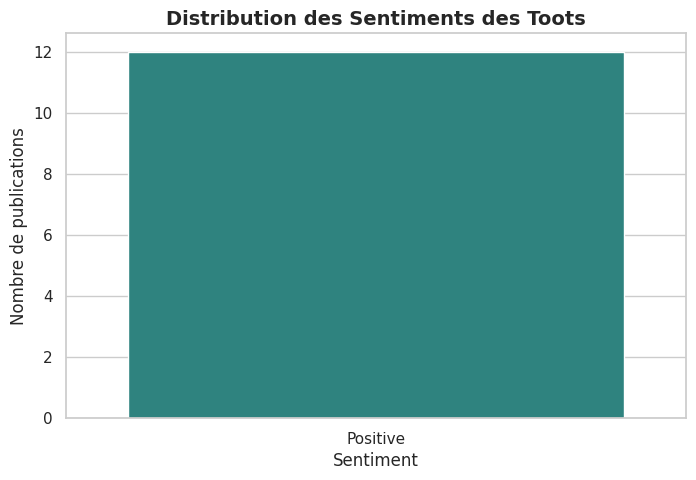

/tmp/ipykernel_16/2639617785.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(query, conn)


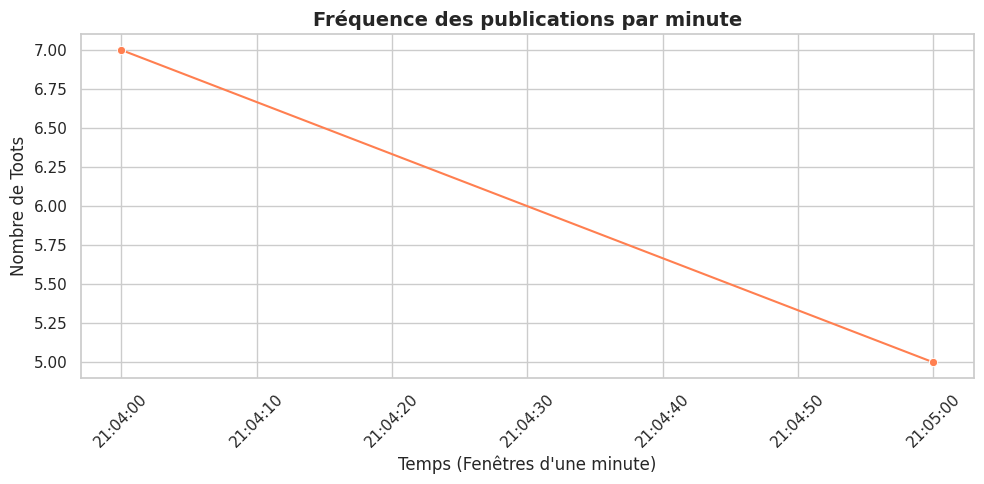

/tmp/ipykernel_16/2639617785.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(query, conn)
/tmp/ipykernel_16/2639617785.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_tags, x='count', y='tag', palette='magma')


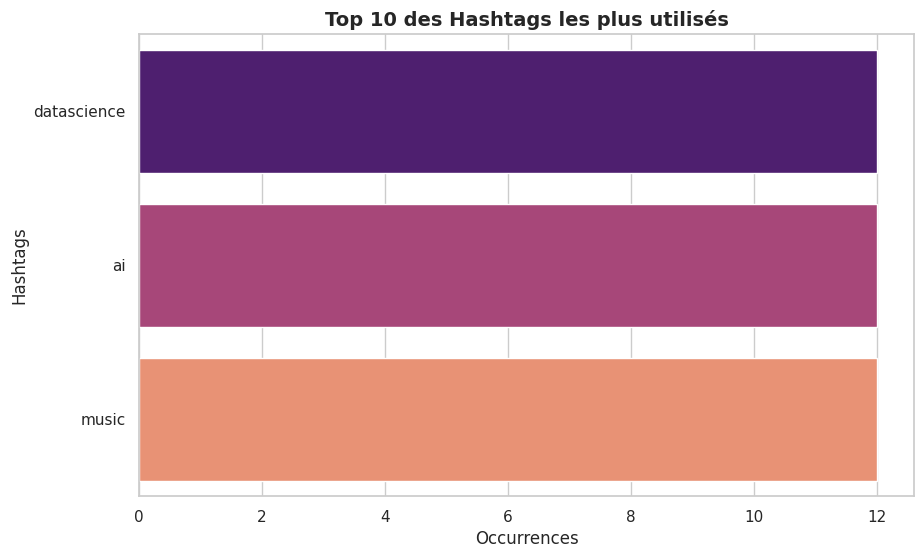

/tmp/ipykernel_16/2639617785.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(query, conn)


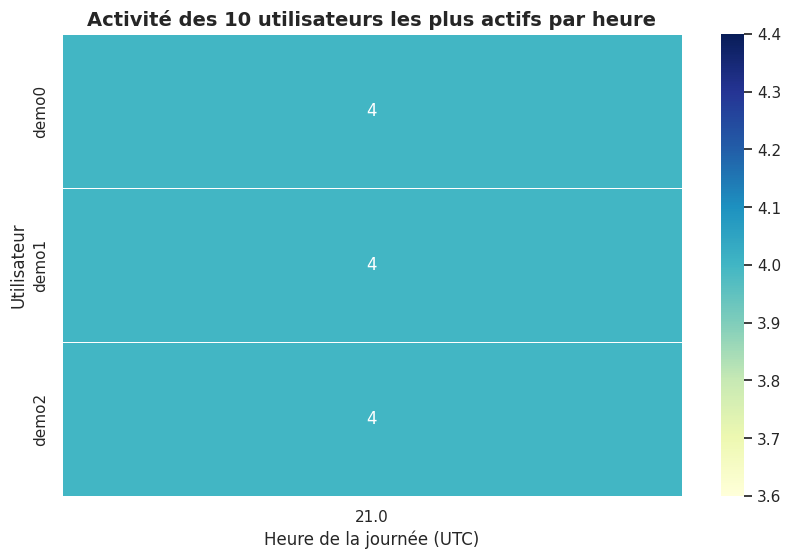